# How much does each scenario factor change the simulated data?

**Method.** One base draw (2-D, bare wall, straight tunnel, no geological structures). Each experiment changes
**one** factor and re-simulates both sources with the same 1 kHz Ricker wavelet. Every variant is compared trace by
trace with the reference (10 shots × 2 receivers, offsets 12-45 m, components s and n).

**Measures** (medians over all traces):

| measure | meaning |
|---|---|
| `|dt_eik|` | change of the eikonal (kinematic) first-arrival time, ms |
| `|dt_fa|` | waveform delay in the first-arrival window (cross-correlation), ms; values near 0.5 ms mean the windows no longer correlate |
| `p90 |dt_eik|` | 90th percentile of the eikonal change: shows effects confined to some traces (e.g. paths crossing a fault) |
| `nrms_fa` | waveform difference in the first-arrival window, % (0 = identical, ~141 = unrelated) |
| `nrms` | waveform difference over the whole 25 ms trace, % |
| `amp_fa` | first-arrival amplitude change, dB |
| `vis_s`, `vis_n` | first-arrival visibility of the variant: strongest level in the first-arrival window relative to the strongest level of the trace, dB (0 = the first arrival is the strongest phase) |

The first-arrival window is [eikonal − 1.2 T, eikonal + 1.5 T] of the reference, T = 1 ms.
Simulations are cached in `runs/experiments/`, so re-running the notebook only re-plots.

In [1]:
%matplotlib inline
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display

from fasim.gen.meta import load_meta
from fasim.gen.sampler import sample_draw, summary
from fasim.gen.build import build_variants
from fasim.gen.simulate import positions
from fasim.gen.plots import plot_models, plot_pair, plot_summary
from fasim.gen.experiments import run_variant, vary, vary_meta, compare, summarise, fa_visibility, table

SEED = 11
FREQ = 1000.0                  # Hz, one Ricker peak frequency for both sources in every run
SOURCES = ("impact", "explosive")
PLOT_COMP = "s"                # along-tunnel velocity: P is visible here for both sources
OVERRIDES = [
    "acquisition.n_receivers=2", "acquisition.receiver_spacing=5.0", "acquisition.gap=12.0",
    "acquisition.n_shots=10", "acquisition.shot_spacing=2.5", "record.length_ms=25",
    "rock.structures.count=0", "grid.field_dx=0.05",            # same rock at every grid spacing
    "sources.impact.direction_jitter_deg=10",
    "tunnel.roughness.amplitude=0.1", "tunnel.roughness.corr_length=1.0", "tunnel.roughness.overbreak_bias=0.3",
    "tunnel.curvature.std_vertical=0", "tunnel.curvature.std_horizontal=0",
]
META = load_meta(overrides=OVERRIDES)
BASE = sample_draw(META, SEED)
NO_TEXTURE = {"rock.texture.large.std": 0.0, "rock.texture.small.std": 0.0}
SMOOTH = vary(BASE, NO_TEXTURE)          # texture-free rock, used where the box itself changes
print(summary(BASE))

seed 11
tunnel  : radius 5.25 m, horizontal straight, vertical straight, face at s = 49.5 m
wall    : roughness 0.10 m rms / 1.0 m, overbreak bias 0.30; concrete 0.11 m, vp 3892
acq     : 2 receivers @ 5.00 m, gap 12.0 m, 10 shots @ 2.50 m, jitter 0.09/0.18/0.11 m, 0 virtual
sources : explosive 508 Hz, impact 1591 Hz (cone 10.0 deg)
rock    : gneiss q=0.36 vp 4836 vs 2509 Q_P 17 fabric foliated x1.9; EDZ 1.38 m x0.69
texture : large 0.022/8.7 m, small 0.029/0.22 m


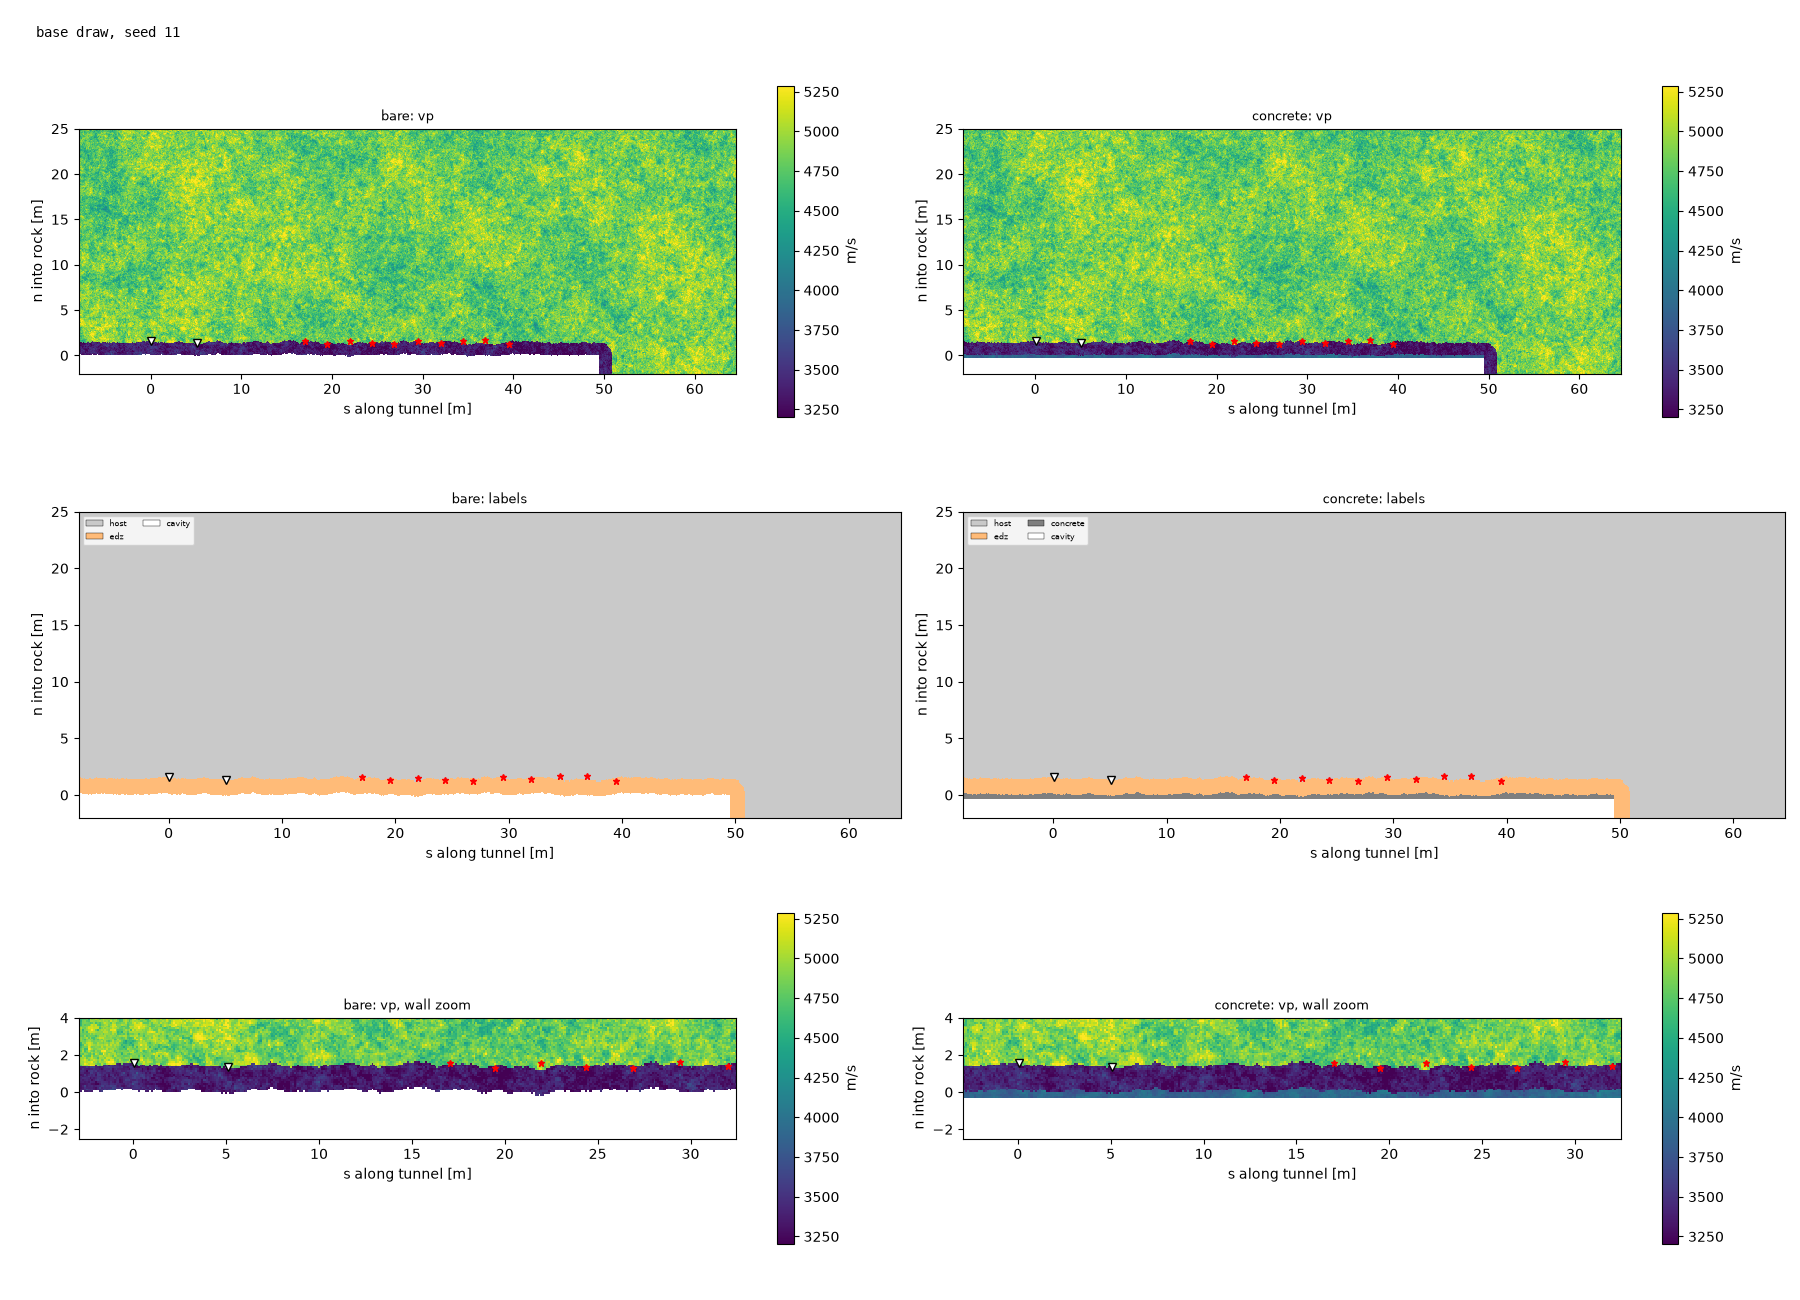

In [2]:
dom, geom, models = build_variants(BASE, META, 2, ["bare", "concrete"])
rcv, shots, _, _ = positions(BASE, geom)
Path("runs/experiments").mkdir(parents=True, exist_ok=True)
plot_models(models, dom, geom, rcv, shots, BASE, "runs/experiments/base_models.png", title=f"base draw, seed {SEED}")
display(Image("runs/experiments/base_models.png", width=900))

In [3]:
RESULTS, RUNS = {}, {}

def experiment(name, params=None, meta=None, wall="bare", sources=SOURCES, ref_params=None, ref_meta=None,
               ref_wall="bare", comps=("s", "n"), plot=True, dims=2, freq=FREQ, record=True):
    params, meta = params or BASE, meta or META
    ref_params, ref_meta = ref_params or BASE, ref_meta or META
    if plot:
        fig, axes = plt.subplots(len(sources), 3, figsize=(15, 3.2 * len(sources)), squeeze=False, sharey="row")
    out = {}
    for i, src in enumerate(sources):
        ref = run_variant(ref_params, ref_meta, dims=dims, wall=ref_wall, source=src, freq=freq, label=f"reference / {src}")
        var = run_variant(params, meta, dims=dims, wall=wall, source=src, freq=freq, label=f"{name} / {src}")
        vis = fa_visibility(var, ("s", "n"))
        out[src] = summarise(compare(ref, var, comps)) | {"vis_s dB": vis["s"], "vis_n dB": vis["n"]}
        RUNS[f"{name} / {src}"] = var
        if record:
            RESULTS[f"{name} / {src}"] = out[src]
        if plot:
            plot_pair(ref, var, 0, PLOT_COMP, axes=axes[i], names=(f"reference, {src}", f"{name}, {src}"))
    if plot:
        fig.suptitle(f"{name}: receiver 0, component {PLOT_COMP}; blue ticks = eikonal", fontsize=10)
        fig.tight_layout()
        plt.show()
    display(Markdown(table({f"{name} / {s}": out[s] for s in sources})))
    return out

## 0. Reference: first-arrival visibility per source

In [4]:
vis = {}
for src in SOURCES:
    r = run_variant(BASE, META, wall="bare", source=src, freq=FREQ, label=f"reference / {src}")
    vis[f"bare wall / {src}"] = fa_visibility(r, ("s", "n", "p"))
    r = run_variant(BASE, META, wall="concrete", source=src, freq=FREQ, label=f"concrete / {src}")
    vis[f"concrete wall / {src}"] = fa_visibility(r, ("s", "n", "p"))
display(Markdown("First-arrival visibility, dB (0 = first arrival is the strongest phase)\n\n" +
                 table({k: {f"vis {c}": v[c] for c in ("s", "n", "p")} for k, v in vis.items()}, "{:.1f}")))

  [cached] reference / impact
  [cached] concrete / impact
  [cached] reference / explosive
  [cached] concrete / explosive


First-arrival visibility, dB (0 = first arrival is the strongest phase)

| experiment | vis s | vis n | vis p |
|---|---|---|---|
| bare wall / impact | -11.5 | -33.1 | -14.1 |
| concrete wall / impact | -14.5 | -36.4 | -20.2 |
| bare wall / explosive | -0.6 | -11.0 | -0.5 |
| concrete wall / explosive | -6.8 | -14.9 | -6.1 |

## 1. Wall: concrete lining vs bare rock

  [cached] reference / impact
  [cached] concrete wall / impact
  [cached] reference / explosive
  [cached] concrete wall / explosive


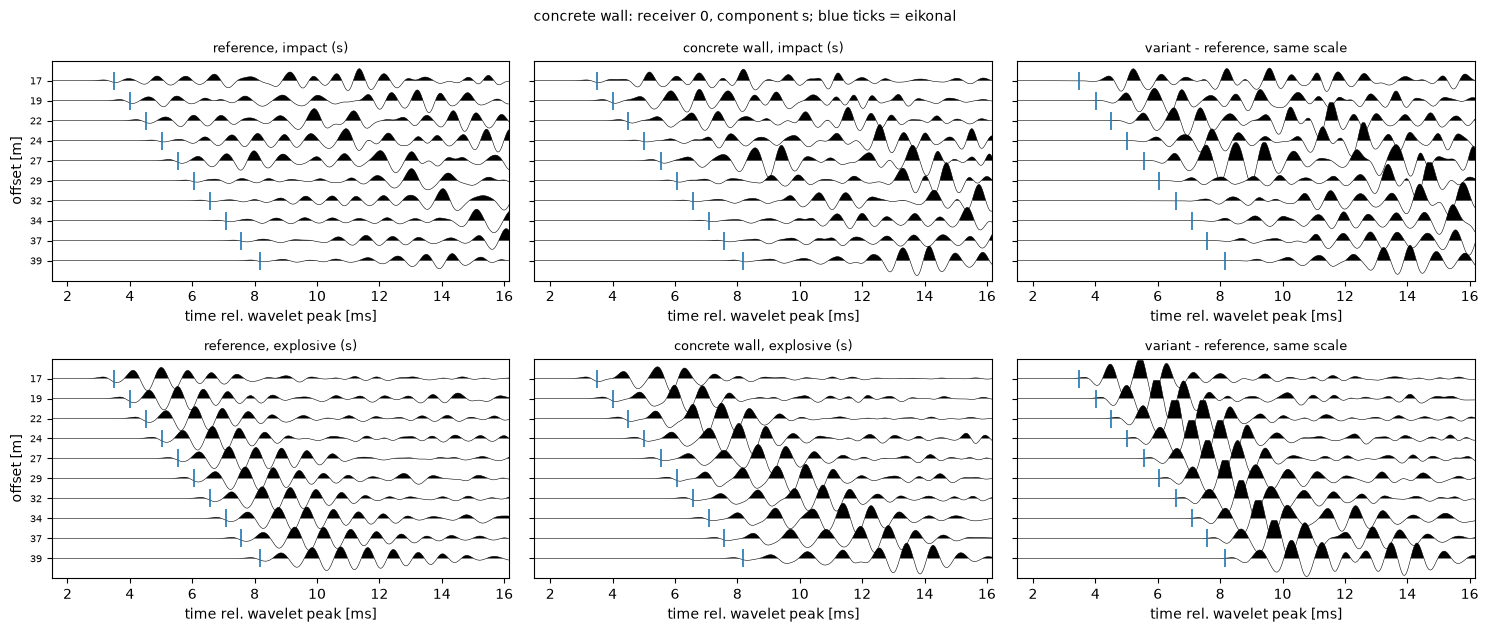

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| concrete wall / impact | 0.00 | 0.00 | 0.19 | 135.26 | 146.97 | 1.86 | -14.48 | -36.40 |
| concrete wall / explosive | 0.00 | 0.00 | 0.19 | 130.24 | 146.61 | -2.36 | -6.76 | -14.92 |

In [5]:
experiment("concrete wall", wall="concrete");

## 2. Tunnel curvature (horizontal, R = 300 m)
Positive curvature bends the tunnel towards the receiver wall. Curvature moves the wall and therefore the box, which would change the random texture realisation; both runs use texture-free rock so only the curvature differs.

  [cached] reference / impact


  [ran 27 s, 2.7 s/shot, 0.22 M cells, 1000 Hz] curved R300 towards / impact
  [cached] reference / explosive


  [ran 25 s, 2.5 s/shot, 0.22 M cells, 1000 Hz] curved R300 towards / explosive


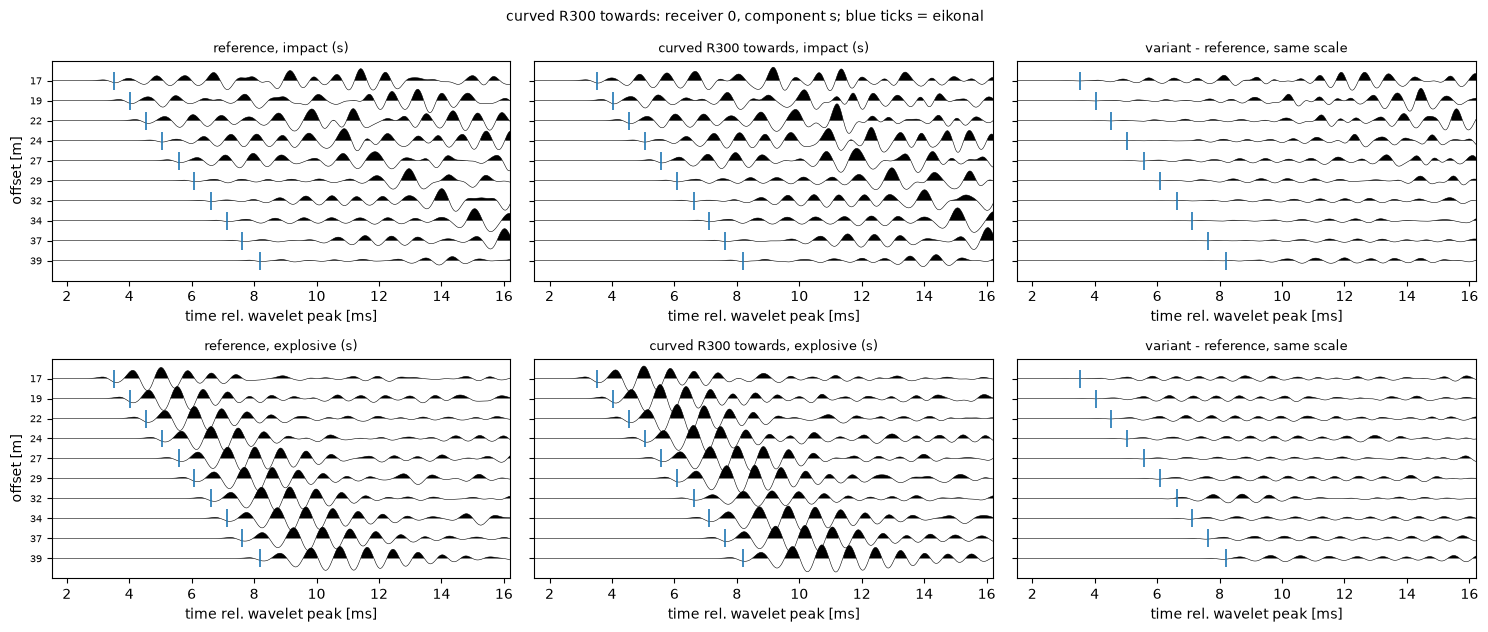

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| curved R300 towards / impact | 0.01 | 0.01 | 0.02 | 26.35 | 35.73 | -0.08 | -11.67 | -32.89 |
| curved R300 towards / explosive | 0.01 | 0.01 | 0.01 | 18.99 | 35.24 | 0.10 | -0.69 | -13.05 |

In [6]:
experiment("curved R300 towards", params=vary(SMOOTH, {"tunnel.curvature_horizontal": 1 / 300}), ref_params=SMOOTH);

  [cached] reference / impact


  [ran 26 s, 2.6 s/shot, 0.22 M cells, 1000 Hz] curved R300 away / impact
  [cached] reference / explosive


  [ran 46 s, 4.6 s/shot, 0.22 M cells, 1000 Hz] curved R300 away / explosive


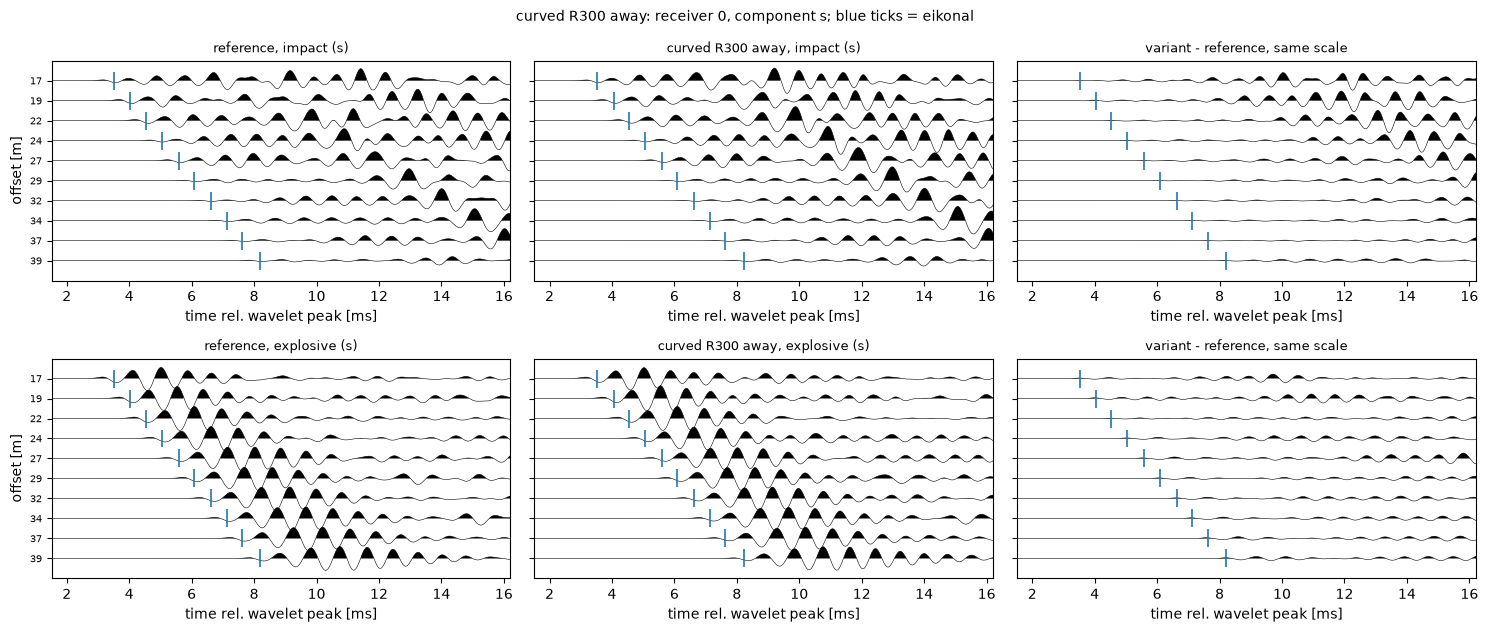

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| curved R300 away / impact | 0.01 | 0.01 | 0.02 | 28.75 | 44.75 | 0.42 | -13.98 | -31.53 |
| curved R300 away / explosive | 0.01 | 0.01 | 0.01 | 17.39 | 34.40 | 0.00 | -0.76 | -8.32 |

In [7]:
experiment("curved R300 away", params=vary(SMOOTH, {"tunnel.curvature_horizontal": -1 / 300}), ref_params=SMOOTH);

## 3. Wall roughness (base: 0.1 m rms)

  [cached] reference / impact
  [cached] smooth wall / impact
  [cached] reference / explosive
  [cached] smooth wall / explosive


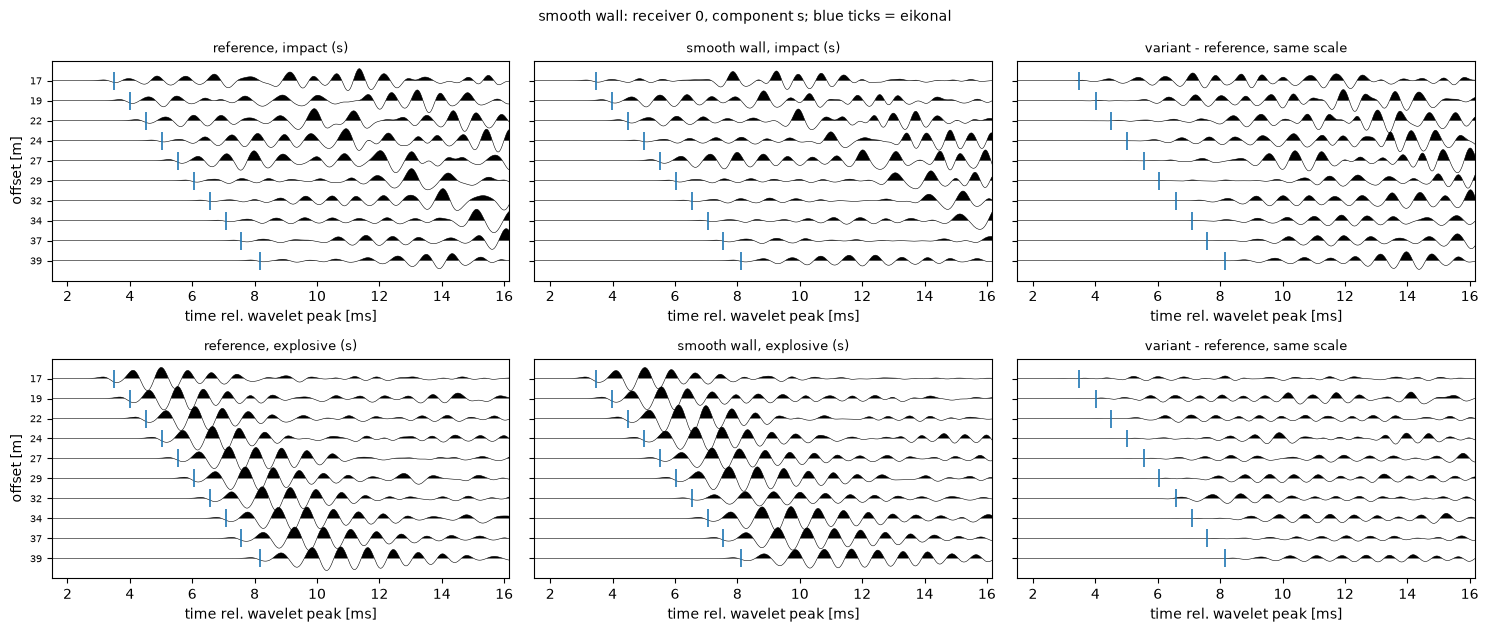

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| smooth wall / impact | 0.02 | 0.04 | 0.02 | 45.56 | 66.26 | -0.65 | -12.75 | -38.91 |
| smooth wall / explosive | 0.02 | 0.04 | 0.01 | 19.84 | 60.52 | -0.42 | -1.04 | -15.91 |

In [8]:
experiment("smooth wall", params=vary(BASE, {"tunnel.roughness.amplitude": 0.0}));

  [cached] reference / impact
  [cached] rough wall 0.3 m / impact
  [cached] reference / explosive
  [cached] rough wall 0.3 m / explosive


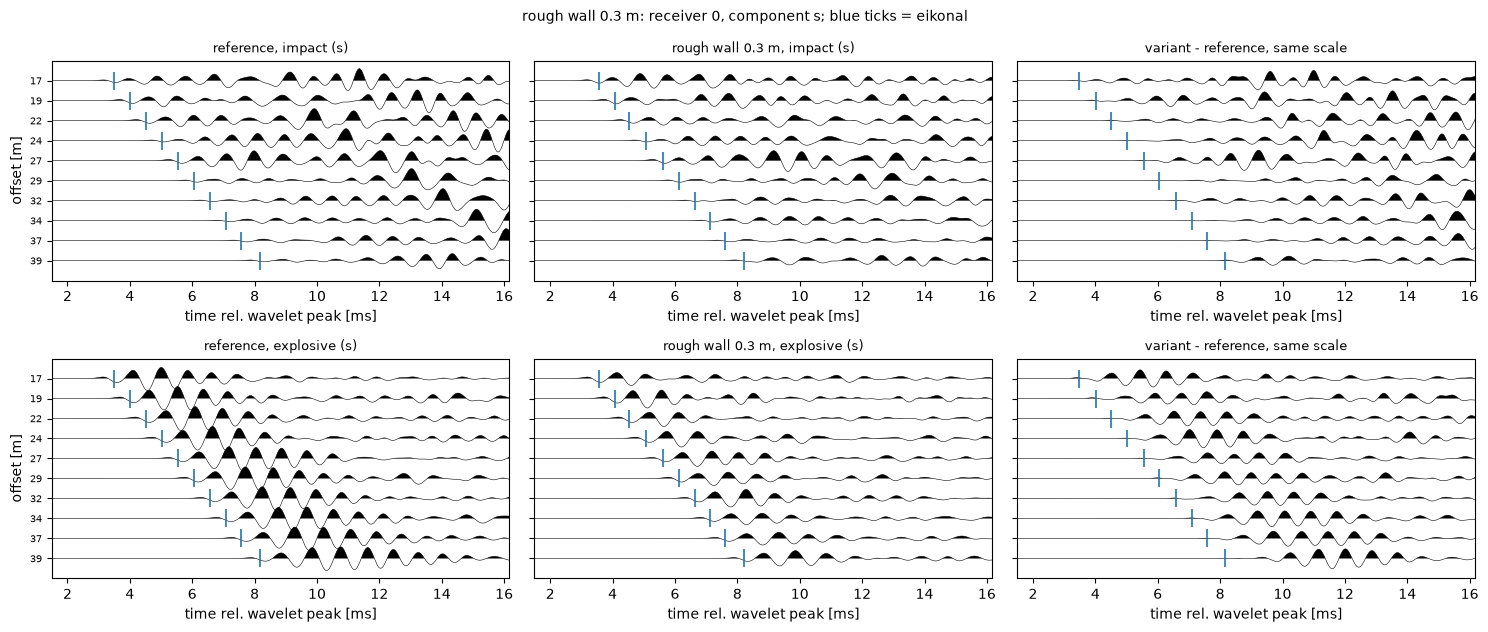

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| rough wall 0.3 m / impact | 0.05 | 0.08 | 0.02 | 54.02 | 146.38 | 0.11 | -5.80 | -18.74 |
| rough wall 0.3 m / explosive | 0.05 | 0.08 | 0.02 | 49.33 | 116.83 | -3.22 | 0.00 | -6.19 |

In [9]:
experiment("rough wall 0.3 m", params=vary(BASE, {"tunnel.roughness.amplitude": 0.3}));

## 4. Excavation damage zone (base: thickness and velocity factor of the draw, printed above)

  [cached] reference / impact
  [cached] no EDZ / impact
  [cached] reference / explosive
  [cached] no EDZ / explosive


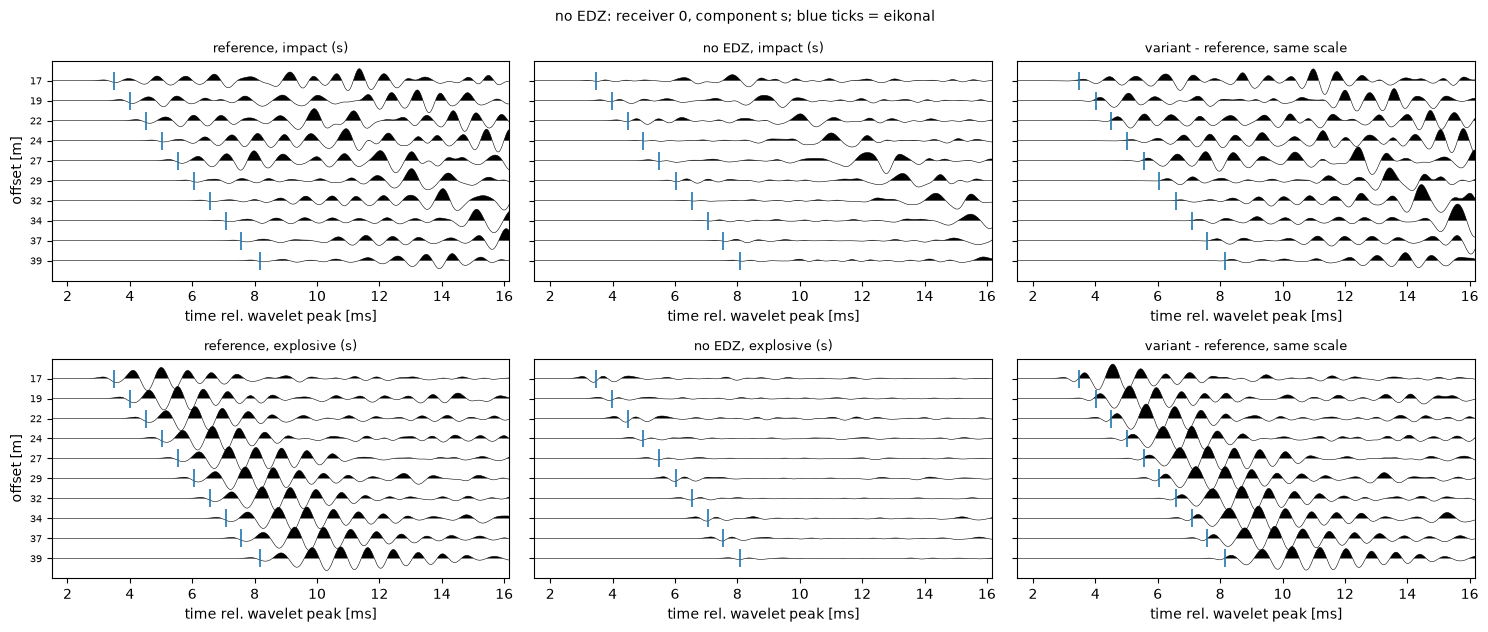

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| no EDZ / impact | 0.04 | 0.06 | 0.36 | 153.85 | 157.48 | -7.33 | -12.99 | -35.71 |
| no EDZ / explosive | 0.04 | 0.06 | 0.44 | 181.89 | 178.72 | -12.08 | 0.00 | -12.10 |

In [10]:
experiment("no EDZ", params=vary(BASE, {"rock.edz.thickness": 0.0}));

  [cached] reference / impact
  [cached] thick EDZ 2 m x0.6 / impact
  [cached] reference / explosive
  [cached] thick EDZ 2 m x0.6 / explosive


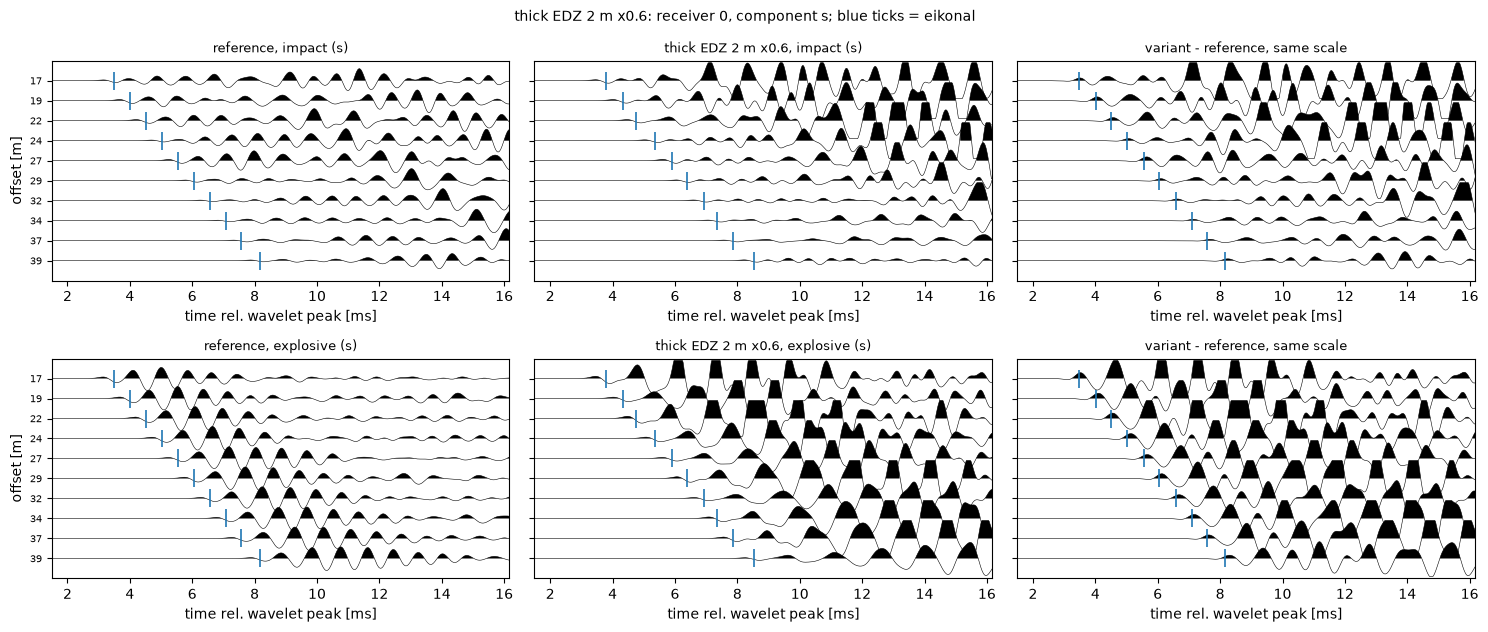

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| thick EDZ 2 m x0.6 / impact | 0.33 | 0.37 | 0.42 | 163.08 | 150.43 | 0.19 | -20.28 | -29.61 |
| thick EDZ 2 m x0.6 / explosive | 0.33 | 0.37 | 0.54 | 164.04 | 153.88 | -3.14 | -9.64 | -17.15 |

In [11]:
experiment("thick EDZ 2 m x0.6", params=vary(BASE, {"rock.edz.thickness": 2.0, "rock.edz.factor": 0.6}));

## 5. Rock texture (small-scale heterogeneity) off

  [cached] reference / impact
  [cached] no texture / impact


  [cached] reference / explosive
  [cached] no texture / explosive


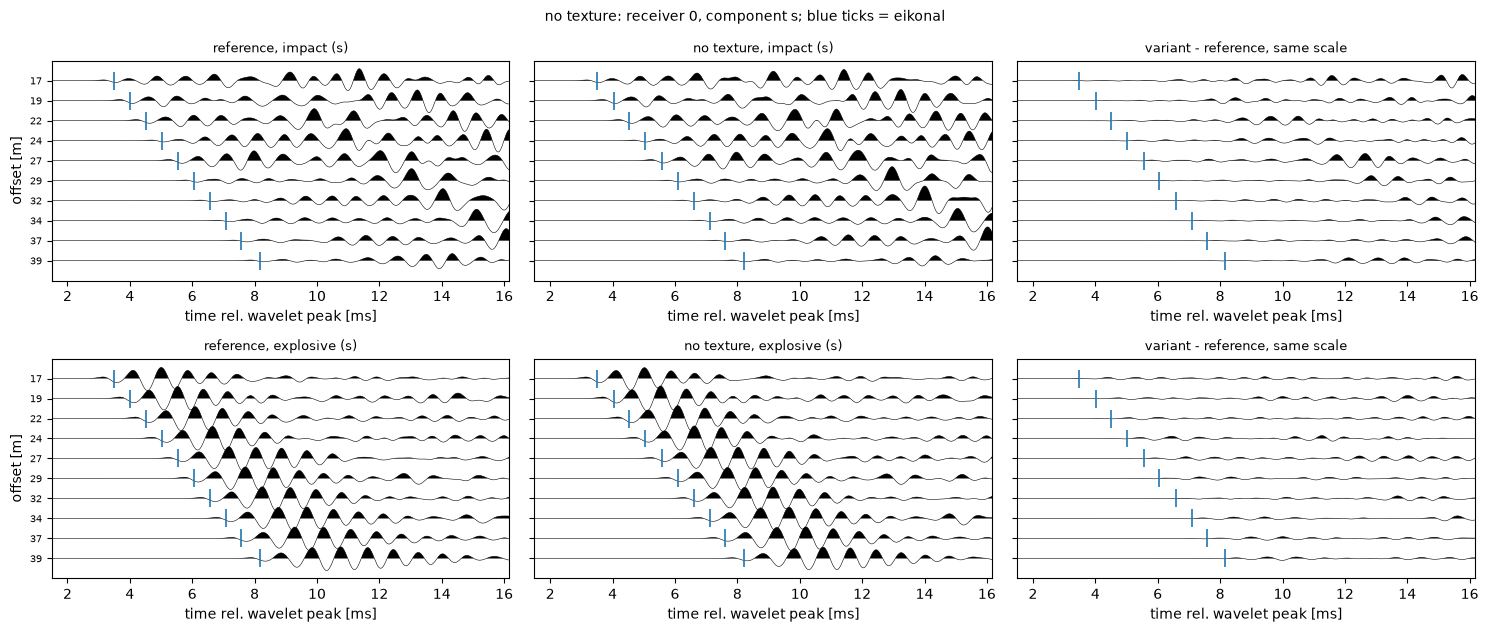

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| no texture / impact | 0.03 | 0.04 | 0.01 | 22.60 | 36.47 | -0.03 | -11.12 | -32.21 |
| no texture / explosive | 0.03 | 0.04 | 0.01 | 15.68 | 26.85 | -0.17 | -0.57 | -11.14 |

In [12]:
experiment("no texture", params=vary(BASE, {"rock.texture.large.std": 0.0, "rock.texture.small.std": 0.0}));

## 6. Hammer direction: blows tilted 30° towards the receivers (impact only)

  [cached] reference / impact
  [cached] impact tilted 30 deg / impact


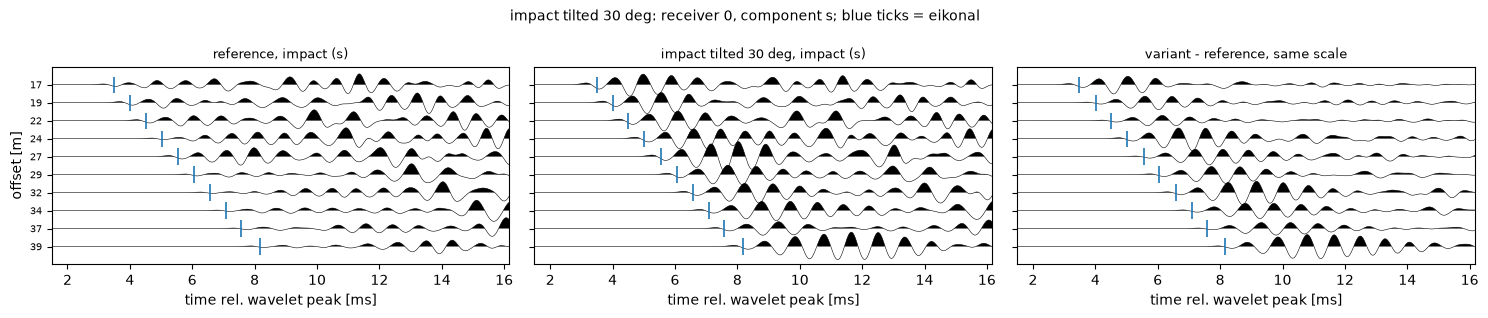

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| impact tilted 30 deg / impact | 0.00 | 0.00 | 0.04 | 113.11 | 35.82 | 9.69 | -1.53 | -24.78 |

In [13]:
n = len(BASE["acquisition"]["shots"])
experiment("impact tilted 30 deg", sources=("impact",),
           params=vary(BASE, {"sources.impact.polar_deg": [30.0] * n, "sources.impact.azimuth_deg": [180.0] * n}));

## 7. Geology for scale: a 1.5 m fault zone crossing the shot line
This is the signal the model has to learn; the nuisance factors above should be compared against it.

  [cached] reference / impact
  [cached] fault zone / impact
  [cached] reference / explosive
  [cached] fault zone / explosive


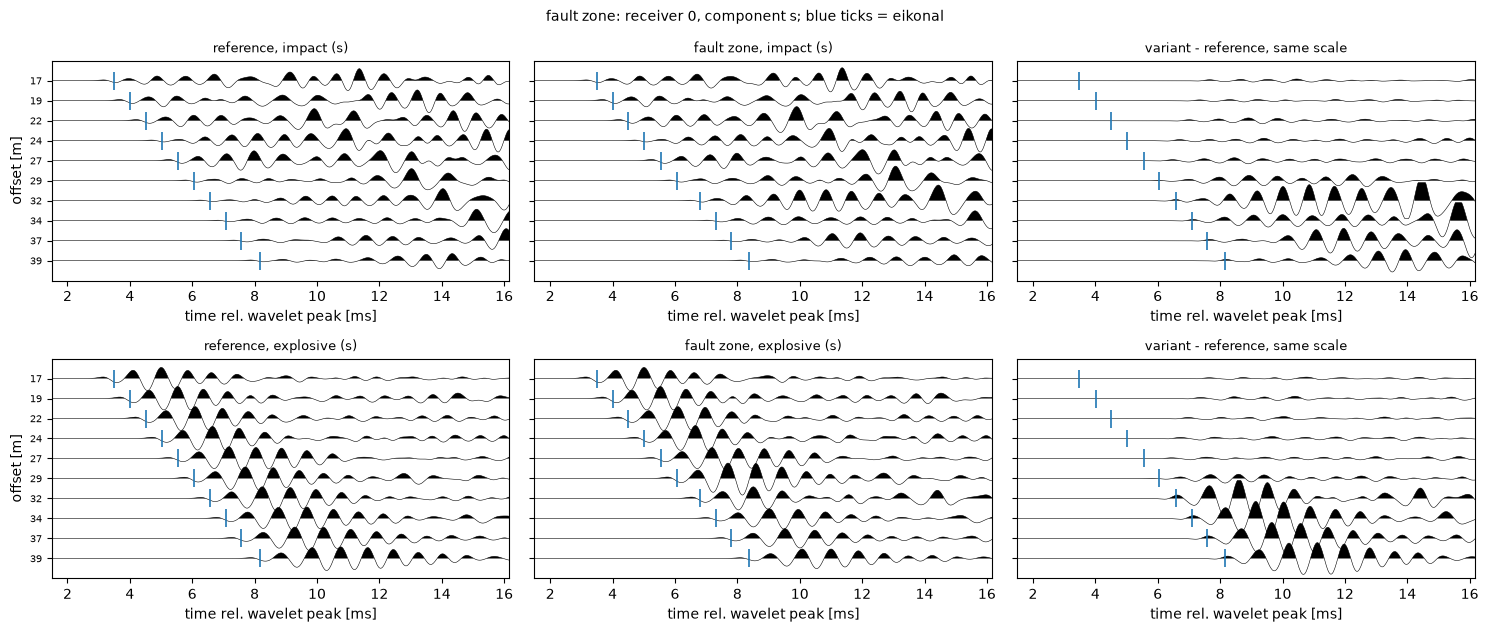

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| fault zone / impact | 0.00 | 0.21 | 0.04 | 49.37 | 34.15 | -0.00 | -10.03 | -32.59 |
| fault zone / explosive | 0.00 | 0.21 | 0.00 | 17.24 | 31.88 | -0.00 | -0.48 | -11.87 |

In [14]:
fault = {"type": "fault_zone", "anchor": {"s": 30.0, "offset": 3.0, "height": 0.0, "in_aperture": True},
         "normal": [0.87, 0.5, 0.0], "width": 1.5, "contrast": 0.3, "halo_factor": 2.0}
experiment("fault zone", params=vary(BASE, {"rock.structures": lambda lst: lst + [fault]}));

## 8. Domain size: is the one-wall box big enough?
Deeper box (45 m instead of 25 m), longer beyond the face (30 m), more tunnel interior (5 m) and more rock behind the receivers (20 m). A different box changes the random texture and wall-roughness realisations, so both runs use texture-free rock and a smooth wall.

  [ran 24 s, 2.4 s/shot, 0.20 M cells, 1000 Hz] reference / impact


  [ran 53 s, 5.3 s/shot, 0.50 M cells, 1000 Hz] bigger domain / impact


  [ran 27 s, 2.7 s/shot, 0.20 M cells, 1000 Hz] reference / explosive


  [ran 59 s, 5.9 s/shot, 0.50 M cells, 1000 Hz] bigger domain / explosive


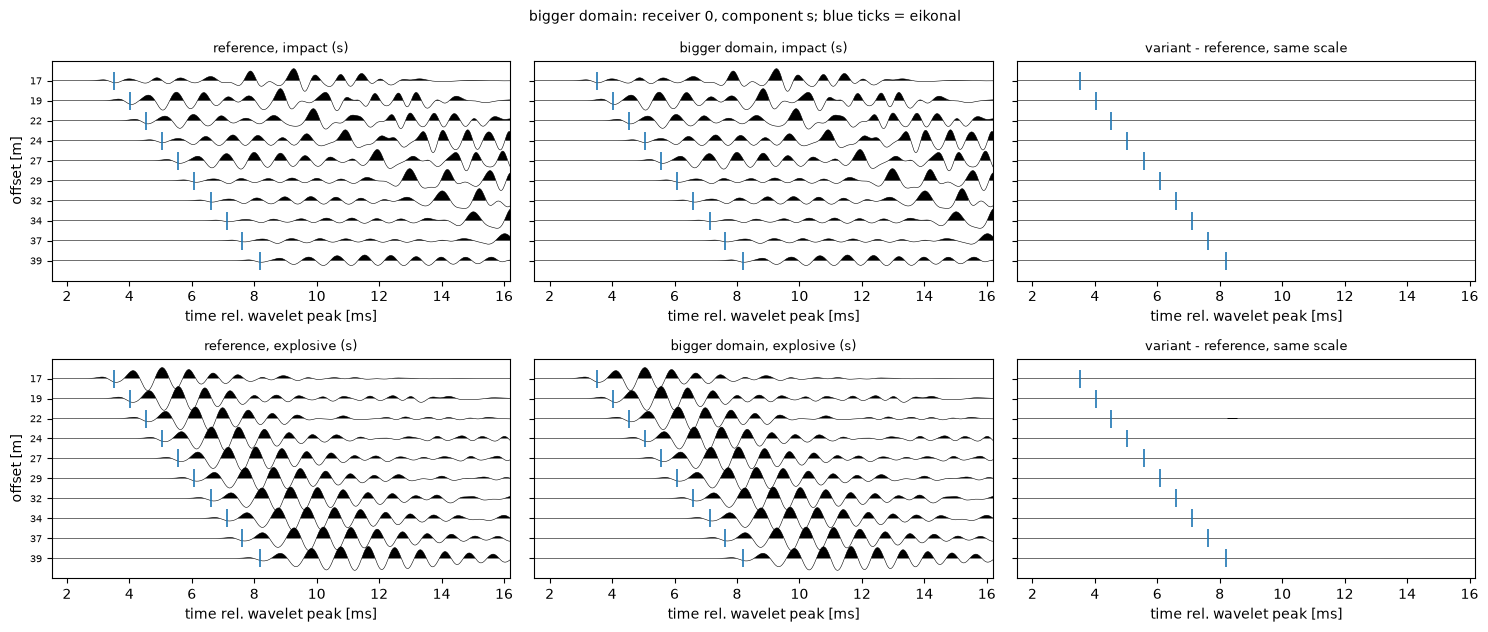

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| bigger domain / impact | 0.00 | 0.00 | 0.00 | 0.00 | 0.02 | -0.00 | -11.73 | -40.07 |
| bigger domain / explosive | 0.00 | 0.00 | 0.00 | 0.00 | 0.04 | 0.00 | -1.16 | -16.92 |

In [15]:
BIG = vary_meta(META, {"domain.depth_into_rock": 45.0, "domain.ahead_of_face": 30.0,
                       "domain.cavity_margin": 5.0, "domain.behind_first_receiver": 20.0})
PLAIN = vary(SMOOTH, {"tunnel.roughness.amplitude": 0.0})
experiment("bigger domain", params=PLAIN, ref_params=PLAIN, meta=BIG);

## 9. Grid density
Reference: dx = 0.05 m. Same rock at every spacing (random fields generated on a fixed 0.05 m grid). At 1 kHz the shortest S wavelength (EDZ, 2.5 × f) is about 0.7 m: 14, 7 and 3.5 cells at dx = 0.05, 0.1 and 0.2 m.

  [cached] reference / impact
  [cached] dx 0.1 vs 0.05 / impact
  [cached] reference / explosive
  [cached] dx 0.1 vs 0.05 / explosive


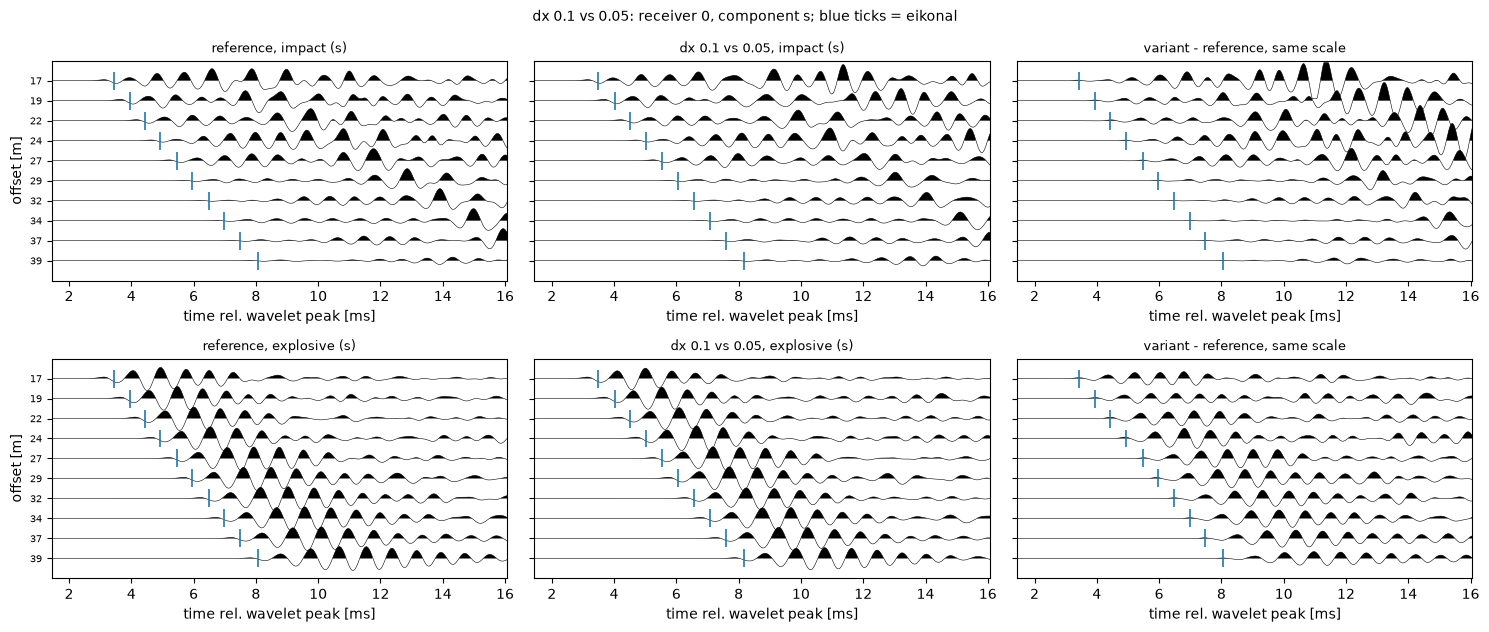

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| dx 0.1 vs 0.05 / impact | 0.08 | 0.10 | 0.04 | 43.53 | 114.02 | 0.16 | -11.48 | -33.12 |
| dx 0.1 vs 0.05 / explosive | 0.08 | 0.10 | 0.05 | 44.98 | 86.76 | 0.28 | -0.59 | -11.04 |

  [cached] reference / impact
  [cached] dx 0.2 vs 0.05 / impact
  [cached] reference / explosive
  [cached] dx 0.2 vs 0.05 / explosive


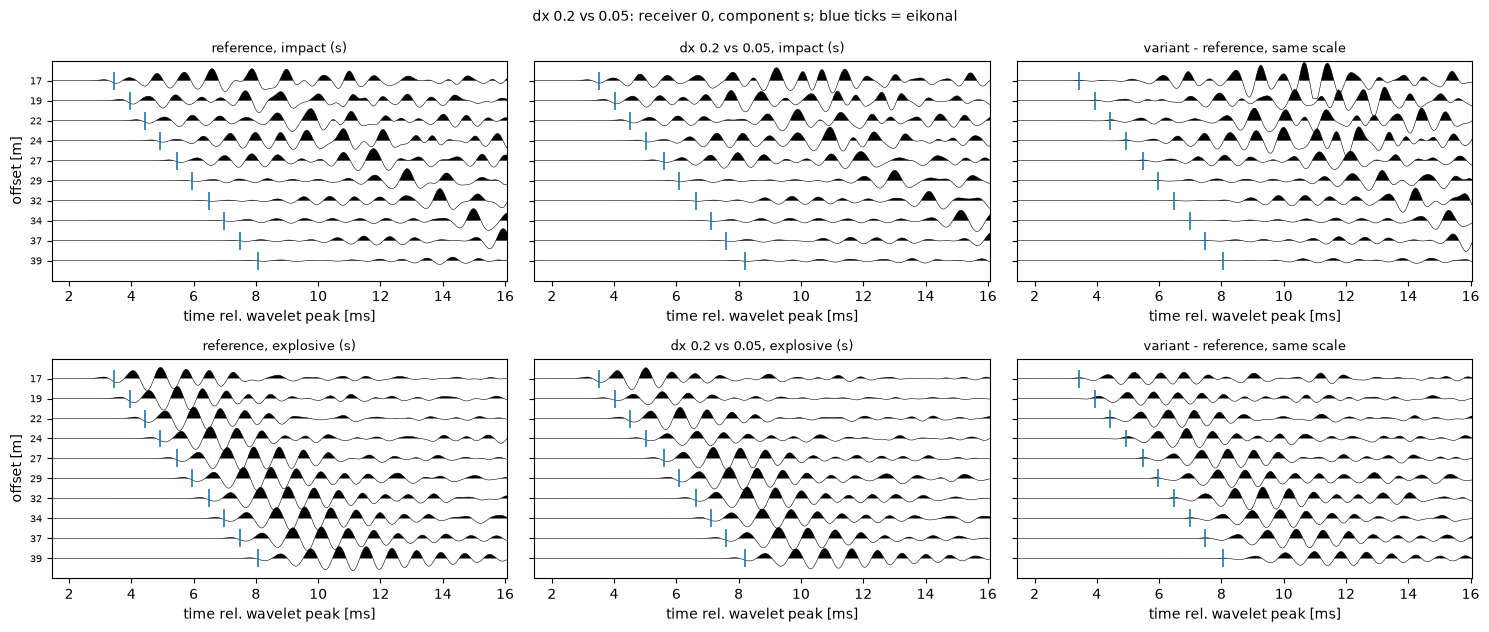

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| dx 0.2 vs 0.05 / impact | 0.11 | 0.13 | 0.05 | 54.33 | 118.65 | 0.61 | -12.91 | -30.83 |
| dx 0.2 vs 0.05 / explosive | 0.11 | 0.13 | 0.06 | 54.86 | 90.19 | -0.46 | -0.45 | -9.80 |

In [16]:
GRID = {dx: vary_meta(META, {"grid.dx_2d": dx}) for dx in (0.05, 0.1, 0.2)}
for dx in (0.1, 0.2):
    experiment(f"dx {dx} vs 0.05", meta=GRID[dx], ref_meta=GRID[0.05])

Same test without rock texture, to separate numerical dispersion from how the texture is sampled:

  [cached] reference / impact
  [cached] dx 0.1 vs 0.05, no texture / impact
  [cached] reference / explosive
  [cached] dx 0.1 vs 0.05, no texture / explosive


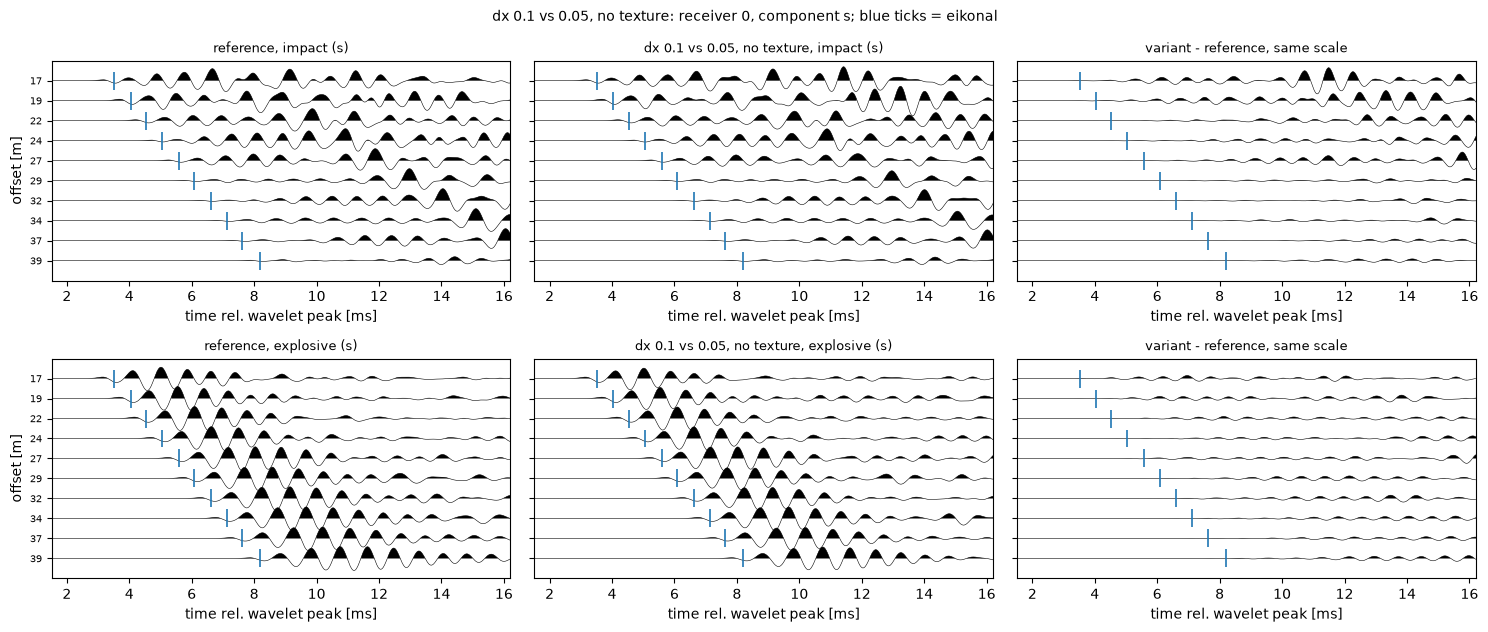

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| dx 0.1 vs 0.05, no texture / impact | 0.01 | 0.01 | 0.01 | 15.11 | 47.70 | -0.26 | -11.12 | -32.21 |
| dx 0.1 vs 0.05, no texture / explosive | 0.01 | 0.01 | 0.00 | 6.76 | 35.84 | 0.02 | -0.57 | -11.14 |

  [cached] reference / impact
  [cached] dx 0.2 vs 0.05, no texture / impact
  [cached] reference / explosive
  [cached] dx 0.2 vs 0.05, no texture / explosive


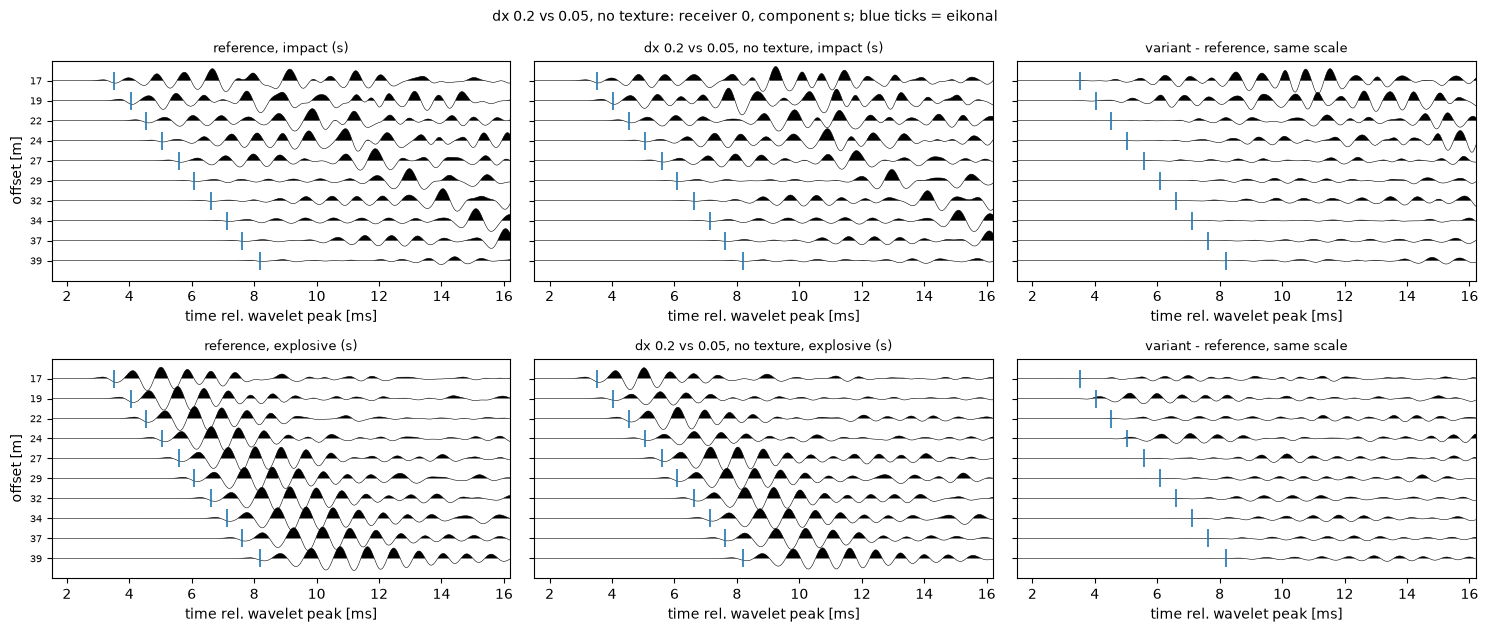

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| dx 0.2 vs 0.05, no texture / impact | 0.01 | 0.02 | 0.02 | 32.16 | 66.83 | -0.07 | -12.49 | -29.45 |
| dx 0.2 vs 0.05, no texture / explosive | 0.01 | 0.02 | 0.00 | 14.49 | 66.61 | -0.60 | -0.52 | -10.29 |

In [17]:
for dx in (0.1, 0.2):
    experiment(f"dx {dx} vs 0.05, no texture", params=SMOOTH, ref_params=SMOOTH, meta=GRID[dx], ref_meta=GRID[0.05])

In [18]:
cost = {}
for dx in (0.05, 0.1, 0.2):
    r = run_variant(BASE, GRID[dx], wall="bare", source="impact", freq=FREQ, verbose=False)
    cost[f"dx {dx}"] = {"cells (M)": r["cells"] / 1e6, "s / shot (M4 CPU)": r["seconds_per_shot"]}
display(Markdown(table(cost)))

| experiment | cells (M) | s / shot (M4 CPU) |
|---|---|---|
| dx 0.05 | 0.78 | 15.85 |
| dx 0.1 | 0.20 | 2.61 |
| dx 0.2 | 0.05 | 0.48 |

## 10. Robustness: the same factors on two other draws
Only the summary measures; no plots.

In [19]:
ROB = {}
for seed in (12, 13):
    b = sample_draw(META, seed)
    bs = vary(b, NO_TEXTURE)
    factors = {
        "concrete wall": dict(wall="concrete"),
        "curved R300 towards": dict(params=vary(bs, {"tunnel.curvature_horizontal": 1 / 300}), ref_params=bs),
        "rough wall 0.3 m": dict(params=vary(b, {"tunnel.roughness.amplitude": 0.3})),
        "thick EDZ 2 m x0.6": dict(params=vary(b, {"rock.edz.thickness": 2.0, "rock.edz.factor": 0.6})),
        "no texture": dict(params=vary(b, {"rock.texture.large.std": 0.0, "rock.texture.small.std": 0.0})),
    }
    for name, kw in factors.items():
        kw.setdefault("params", b)
        kw.setdefault("ref_params", b)
        out = experiment(f"{name} [seed {seed}]", plot=False, record=False, **kw)
        for src, v in out.items():
            ROB[f"{name} / {src} / seed {seed}"] = v

  [cached] reference / impact
  [cached] concrete wall [seed 12] / impact
  [cached] reference / explosive
  [cached] concrete wall [seed 12] / explosive


| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| concrete wall [seed 12] / impact | 0.00 | 0.00 | 0.15 | 124.78 | 121.50 | 4.46 | -6.14 | -26.62 |
| concrete wall [seed 12] / explosive | 0.00 | 0.00 | 0.09 | 99.09 | 110.54 | 0.91 | 0.00 | -8.14 |

  [cached] reference / impact


  [ran 31 s, 3.1 s/shot, 0.22 M cells, 1000 Hz] curved R300 towards [seed 12] / impact
  [cached] reference / explosive


  [ran 30 s, 3.0 s/shot, 0.22 M cells, 1000 Hz] curved R300 towards [seed 12] / explosive


...

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| rough wall 0.3 m [seed 13] / impact | 0.03 | 0.05 | 0.02 | 43.85 | 137.45 | -1.39 | -11.24 | -23.81 |
| rough wall 0.3 m [seed 13] / explosive | 0.03 | 0.05 | 0.02 | 41.97 | 114.30 | -2.84 | 0.00 | -8.85 |

  [cached] reference / impact
  [cached] thick EDZ 2 m x0.6 [seed 13] / impact
  [cached] reference / explosive
  [cached] thick EDZ 2 m x0.6 [seed 13] / explosive


| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| thick EDZ 2 m x0.6 [seed 13] / impact | 0.34 | 0.38 | 0.43 | 174.05 | 153.53 | 2.66 | -23.96 | -27.08 |
| thick EDZ 2 m x0.6 [seed 13] / explosive | 0.34 | 0.38 | 0.54 | 162.19 | 162.42 | -0.46 | -13.31 | -16.24 |

  [cached] reference / impact
  [cached] no texture [seed 13] / impact
  [cached] reference / explosive
  [cached] no texture [seed 13] / explosive


| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| no texture [seed 13] / impact | 0.21 | 0.25 | 0.28 | 167.60 | 155.17 | 1.13 | -16.29 | -39.10 |
| no texture [seed 13] / explosive | 0.21 | 0.25 | 0.30 | 167.72 | 172.18 | 2.64 | -0.40 | -15.64 |

## 11. 2-D vs 3-D (impact, 500 Hz, reduced box, 4 shots)
3-D is expensive on a laptop CPU, so the box is smaller (12 m deep, ±8 m vertical) and the frequency lower (dx 0.25 m in 3-D). Only timing and visibility are meaningful here: 2-D and 3-D waveforms differ by construction (line source vs point source).

  [cached] 2-D
  [cached] 3-D


| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| 3-D vs 2-D / impact | 0.10 | 0.13 | 0.27 | 182.73 | 158.54 | -23.10 | -14.54 | -17.38 |
| 2-D (reference) / impact | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 | -10.66 | -14.84 |

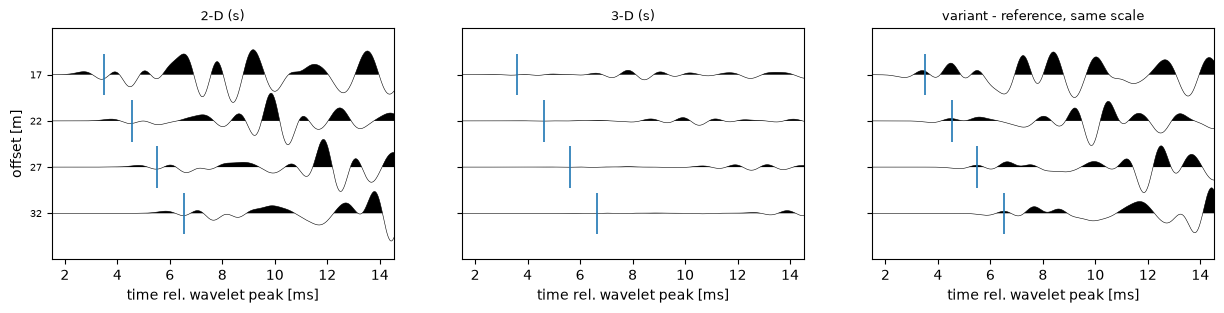

runtime: 2-D 4 s, 3-D 377 s (0.82 M cells)


In [20]:
RUN_3D = True
if RUN_3D:
    M23 = vary_meta(META, {"acquisition.n_shots": 4, "acquisition.shot_spacing": 5.0, "grid.field_dx": None,
                           "grid.dx_3d": 0.25, "domain.depth_into_rock": 12.0, "domain.vertical_half": 8.0,
                           "domain.ahead_of_face": 5.0})
    B23 = sample_draw(M23, SEED)
    r2 = run_variant(B23, M23, dims=2, wall="bare", source="impact", freq=500.0, label="2-D")
    r3 = run_variant(B23, M23, dims=3, wall="bare", source="impact", freq=500.0, label="3-D")
    v2, v3 = fa_visibility(r2, ("s", "n")), fa_visibility(r3, ("s", "n"))
    s23 = summarise(compare(r2, r3, ("s", "n")))
    display(Markdown(table({"3-D vs 2-D / impact": s23 | {"vis_s dB": v3["s"], "vis_n dB": v3["n"]},
                            "2-D (reference) / impact": {k: 0.0 for k in s23} | {"vis_s dB": v2["s"], "vis_n dB": v2["n"]}})))
    fig, axes = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
    plot_pair(r2, r3, 0, "s", axes=axes, names=("2-D", "3-D"))
    plt.show()
    print(f"runtime: 2-D {r2['runtime_s']:.0f} s, 3-D {r3['runtime_s']:.0f} s ({r3['cells'] / 1e6:.2f} M cells)")

## 12. Summary

| experiment | |dt_eik| ms | p90 |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB | vis_s dB | vis_n dB |
|---|---|---|---|---|---|---|---|---|
| no EDZ / explosive | 0.04 | 0.06 | 0.44 | 181.89 | 178.72 | -12.08 | 0.00 | -12.10 |
| thick EDZ 2 m x0.6 / explosive | 0.33 | 0.37 | 0.54 | 164.04 | 153.88 | -3.14 | -9.64 | -17.15 |
| thick EDZ 2 m x0.6 / impact | 0.33 | 0.37 | 0.42 | 163.08 | 150.43 | 0.19 | -20.28 | -29.61 |
| no EDZ / impact | 0.04 | 0.06 | 0.36 | 153.85 | 157.48 | -7.33 | -12.99 | -35.71 |
| concrete wall / impact | 0.00 | 0.00 | 0.19 | 135.26 | 146.97 | 1.86 | -14.48 | -36.40 |
| concrete wall / explosive | 0.00 | 0.00 | 0.19 | 130.24 | 146.61 | -2.36 | -6.76 | -14.92 |
| impact tilted 30 deg / impact | 0.00 | 0.00 | 0.04 | 113.11 | 35.82 | 9.69 | -1.53 | -24.78 |
| dx 0.2 vs 0.05 / explosive | 0.11 | 0.13 | 0.06 | 54.86 | 90.19 | -0.46 | -0.45 | -9.80 |
| dx 0.2 vs 0.05 / impact | 0.11 | 0.13 | 0.05 | 54.33 | 118.65 | 0.61 | -12.91 | -30.83 |
| rough wall 0.3 m / impact | 0.05 | 0.08 | 0.02 | 54.02 | 146.38 | 0.11 | -5.80 | -18.74 |
| fault zone / impact | 0.00 | 0.21 | 0.04 | 49.37 | 34.15 | -0.00 | -10.03 | -32.59 |
| rough wall 0.3 m / explosive | 0.05 | 0.08 | 0.02 | 49.33 | 116.83 | -3.22 | 0.00 | -6.19 |
| smooth wall / impact | 0.02 | 0.04 | 0.02 | 45.56 | 66.26 | -0.65 | -12.75 | -38.91 |
| dx 0.1 vs 0.05 / explosive | 0.08 | 0.10 | 0.05 | 44.98 | 86.76 | 0.28 | -0.59 | -11.04 |
| dx 0.1 vs 0.05 / impact | 0.08 | 0.10 | 0.04 | 43.53 | 114.02 | 0.16 | -11.48 | -33.12 |
| dx 0.2 vs 0.05, no texture / impact | 0.01 | 0.02 | 0.02 | 32.16 | 66.83 | -0.07 | -12.49 | -29.45 |
| curved R300 away / impact | 0.01 | 0.01 | 0.02 | 28.75 | 44.75 | 0.42 | -13.98 | -31.53 |
| curved R300 towards / impact | 0.01 | 0.01 | 0.02 | 26.35 | 35.73 | -0.08 | -11.67 | -32.89 |
| no texture / impact | 0.03 | 0.04 | 0.01 | 22.60 | 36.47 | -0.03 | -11.12 | -32.21 |
| smooth wall / explosive | 0.02 | 0.04 | 0.01 | 19.84 | 60.52 | -0.42 | -1.04 | -15.91 |
| curved R300 towards / explosive | 0.01 | 0.01 | 0.01 | 18.99 | 35.24 | 0.10 | -0.69 | -13.05 |
| curved R300 away / explosive | 0.01 | 0.01 | 0.01 | 17.39 | 34.40 | 0.00 | -0.76 | -8.32 |
| fault zone / explosive | 0.00 | 0.21 | 0.00 | 17.24 | 31.88 | -0.00 | -0.48 | -11.87 |
| no texture / explosive | 0.03 | 0.04 | 0.01 | 15.68 | 26.85 | -0.17 | -0.57 | -11.14 |
| dx 0.1 vs 0.05, no texture / impact | 0.01 | 0.01 | 0.01 | 15.11 | 47.70 | -0.26 | -11.12 | -32.21 |
| dx 0.2 vs 0.05, no texture / explosive | 0.01 | 0.02 | 0.00 | 14.49 | 66.61 | -0.60 | -0.52 | -10.29 |
| dx 0.1 vs 0.05, no texture / explosive | 0.01 | 0.01 | 0.00 | 6.76 | 35.84 | 0.02 | -0.57 | -11.14 |
| bigger domain / impact | 0.00 | 0.00 | 0.00 | 0.00 | 0.02 | -0.00 | -11.73 | -40.07 |
| bigger domain / explosive | 0.00 | 0.00 | 0.00 | 0.00 | 0.04 | 0.00 | -1.16 | -16.92 |

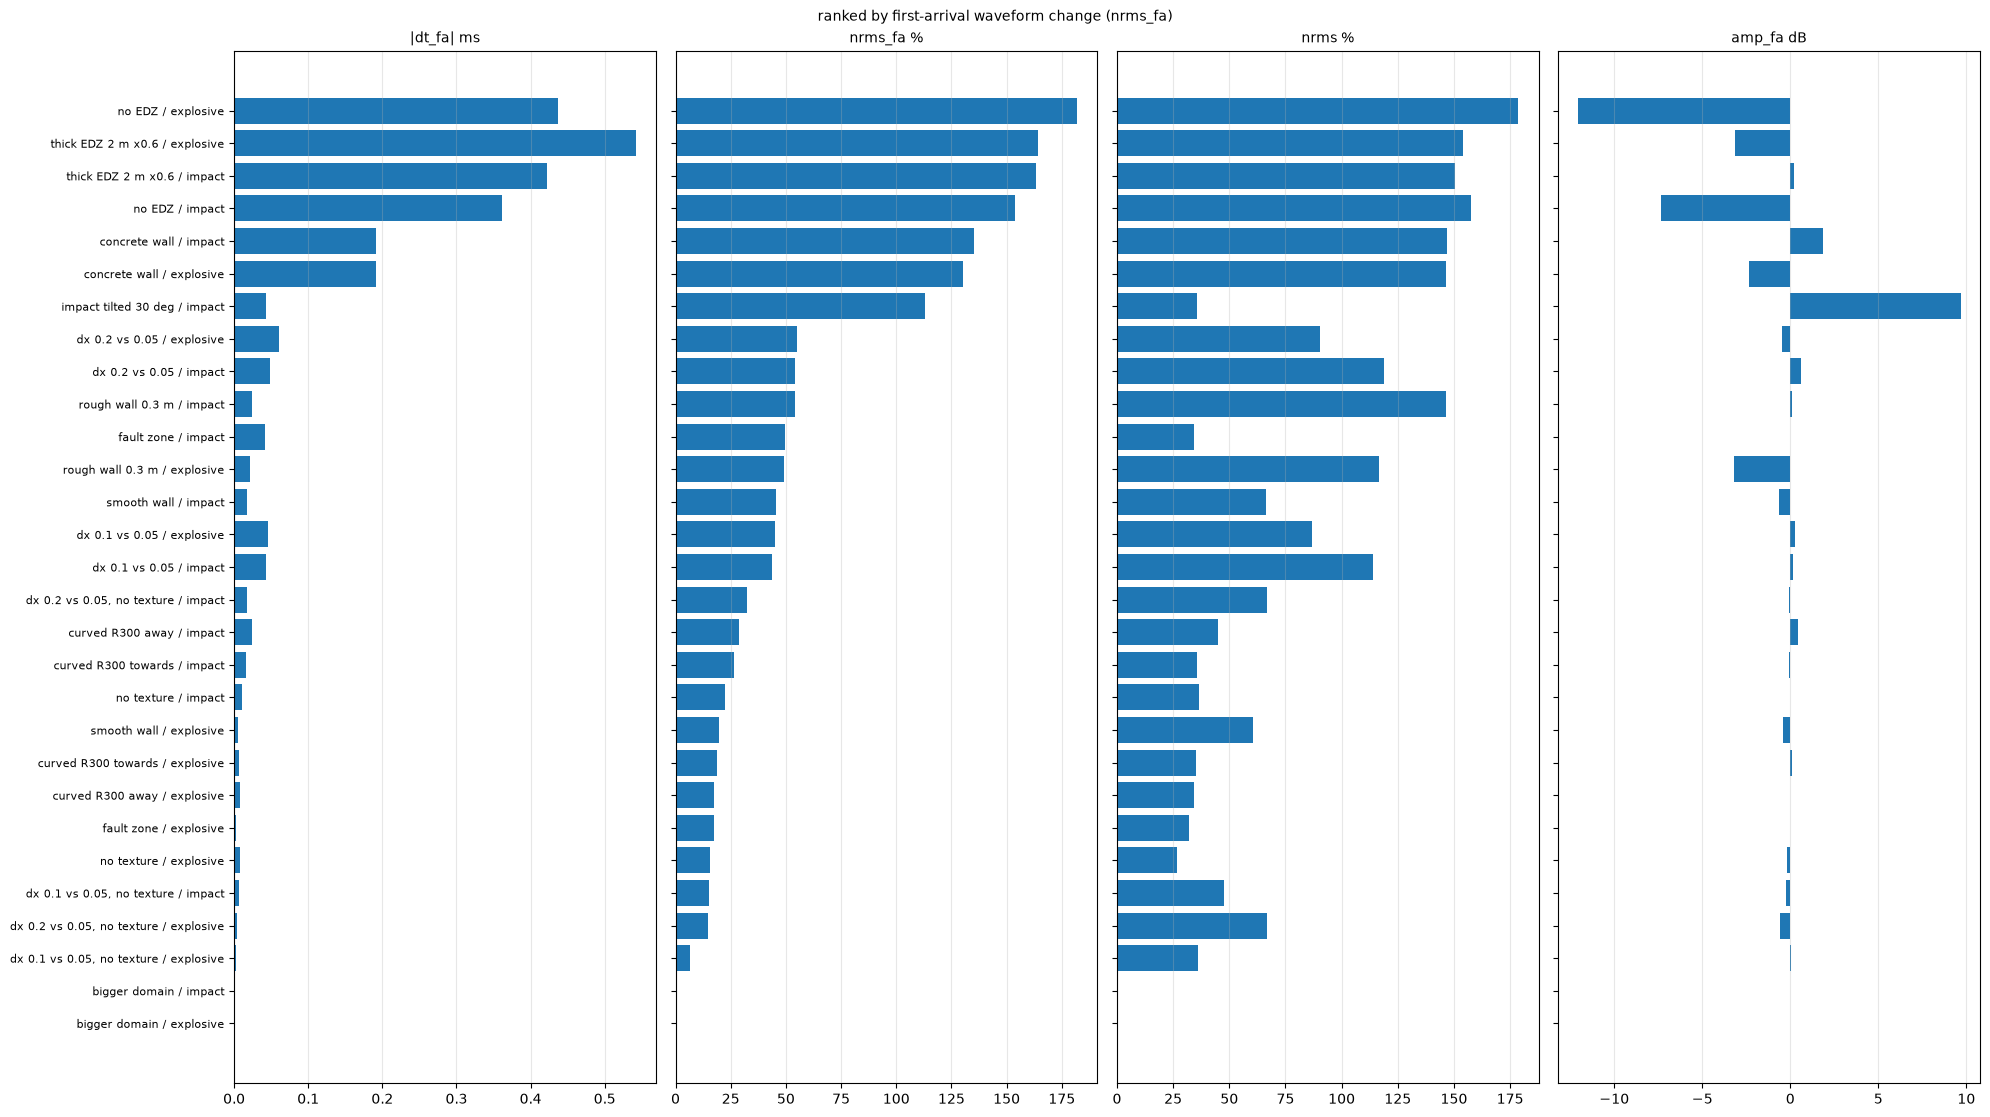

Robustness (seeds 12, 13)

| experiment | |dt_fa| ms | nrms_fa % | nrms % | amp_fa dB |
|---|---|---|---|---|
| concrete wall / impact / seed 12 | 0.15 | 124.78 | 121.50 | 4.46 |
| concrete wall / explosive / seed 12 | 0.09 | 99.09 | 110.54 | 0.91 |
| curved R300 towards / impact / seed 12 | 0.01 | 22.22 | 32.98 | 0.09 |
| curved R300 towards / explosive / seed 12 | 0.01 | 19.07 | 27.75 | -0.01 |
| rough wall 0.3 m / impact / seed 12 | 0.03 | 58.68 | 148.95 | -0.32 |
| rough wall 0.3 m / explosive / seed 12 | 0.04 | 83.78 | 130.55 | -2.16 |
| thick EDZ 2 m x0.6 / impact / seed 12 | 0.27 | 163.51 | 172.09 | 7.29 |
| thick EDZ 2 m x0.6 / explosive / seed 12 | 0.15 | 133.98 | 181.09 | 9.19 |
| no texture / impact / seed 12 | 0.00 | 18.96 | 33.71 | 0.12 |
| no texture / explosive / seed 12 | 0.00 | 19.49 | 34.11 | 0.36 |
| concrete wall / impact / seed 13 | 0.31 | 163.19 | 156.56 | 5.03 |
| concrete wall / explosive / seed 13 | 0.31 | 167.79 | 154.54 | -1.97 |
| curved R300 towards / impact / seed 13 | 0.01 | 22.27 | 29.28 | 0.24 |
| curved R300 towards / explosive / seed 13 | 0.01 | 15.40 | 30.63 | 0.11 |
| rough wall 0.3 m / impact / seed 13 | 0.02 | 43.85 | 137.45 | -1.39 |
| rough wall 0.3 m / explosive / seed 13 | 0.02 | 41.97 | 114.30 | -2.84 |
| thick EDZ 2 m x0.6 / impact / seed 13 | 0.43 | 174.05 | 153.53 | 2.66 |
| thick EDZ 2 m x0.6 / explosive / seed 13 | 0.54 | 162.19 | 162.42 | -0.46 |
| no texture / impact / seed 13 | 0.28 | 167.60 | 155.17 | 1.13 |
| no texture / explosive / seed 13 | 0.30 | 167.72 | 172.18 | 2.64 |

In [21]:
order = sorted(RESULTS, key=lambda k: -RESULTS[k]["nrms_fa %"])
display(Markdown(table({k: RESULTS[k] for k in order})))
plot_summary({k: RESULTS[k] for k in order}, keys=("|dt_fa| ms", "nrms_fa %", "nrms %", "amp_fa dB"),
             title="ranked by first-arrival waveform change (nrms_fa)");
plt.show()
display(Markdown("Robustness (seeds 12, 13)\n\n" + table({k: {c: ROB[k][c] for c in ("|dt_fa| ms", "nrms_fa %", "nrms %", "amp_fa dB")} for k in ROB})))

## Conclusions

Ranked by how much each factor changes the **first-arrival waveform** (`nrms_fa`); timing changes in brackets.
One base draw at 1 kHz, five factors repeated on two more draws; medians over 20 traces × 2 components.

1. **EDZ: the largest effect.** Removing or thickening it changes the first-arrival waveform by 150-180 % on every draw.
   A 2 m EDZ at ×0.6 delays the first arrival by 0.25-0.34 ms, because shots and receivers (1.5 m deep) then sit inside
   the slow zone, and lowers first-arrival visibility by 9-20 dB. Where the sensors are relative to the EDZ matters most.
2. **Concrete wall: large.** 100-168 % on all three draws (waveform delay 0.1-0.3 ms; eikonal unchanged).
   First-arrival visibility drops 3-6 dB.
3. **Hammer direction: large for amplitude.** Tilting the blows 30° towards the receivers raises the first-arrival
   amplitude by 10 dB: visibility on component s goes from −11.5 to −1.5 dB. Timing unchanged.
4. **Wall roughness: moderate.** 0.3 m rms changes the first arrival by 42-84 % and the whole trace by 114-149 %.
   It scatters the later wall waves, so the first arrival becomes 5-9 dB more visible. Smooth vs 0.1 m: 20-46 %.
5. **Curvature (R = 300 m): small.** 15-29 % on all draws, timing ≤ 0.02 ms: about the size of the dx 0.1 m numerical error.
6. **Rock texture: small, unless it is strong and long-wavelength.** 16-23 % on two draws; on seed 13 (6.6 %, 19 m
   correlation) removing it shifts traveltimes by 0.21 ms, so there it acts like geology.
7. **Domain size: none.** A box twice as deep and longer gives identical traces (≤ 0.04 %). The 25 m one-wall box is enough.

**Geology for scale.** A 1.5 m fault zone (−30 %) crossing the shot line changes the first arrival by only 17-49 %
(median) but shifts traveltimes by up to 0.21 ms on the crossing paths (p90). The near-wall factors (EDZ, concrete,
hammer direction) change the first-arrival waveform **more than the fault does**; the fault shows mainly in timing.
For the dataset this means the near-wall factors must be varied widely, and labels should be kinematic.

**Grid density.** With texture-free rock, dx 0.1 m differs from the 0.05 m reference by 7-15 % at the first arrival
and dx 0.2 m by 14-32 %; timing errors stay ≤ 0.02 ms. With texture both grids differ by 44-55 %: the difference
then comes from how the rough texture is sampled on the grid, not from numerical dispersion. Cost per shot on the
M4 CPU: 0.5 s (dx 0.2), 2.6 s (dx 0.1), 15.9 s (dx 0.05). dx 0.1 m is adequate at 1 kHz; texture should be
band-limited to the grid so that the medium itself does not depend on dx.

**Sources.** The explosive first arrival is the strongest phase on components s and p (−0.5 dB). The impact first
arrival is 11-14 dB below the strongest phase on s and 33 dB below on n.

**2-D vs 3-D** (500 Hz, small box, independent texture realisations). Traveltimes differ by 0.1 ms; the waveforms
are unrelated (line vs point source), and the first arrival is 2-4 dB less visible in 3-D. 3-D costs 94 s per shot
on the CPU against 1 s in 2-D.

**Caveats.** 2-D, one frequency, one acquisition layout, medians over few traces; the robustness check covers five
factors on two extra draws. Random fields depend on the box bounds, which is why curvature and domain size were
tested on texture-free rock.
